In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Leemos los csv creados en mainpisa y guardados en la carpeta datos
df_valencia25=pd.read_csv('data/pisa_valencia25.csv')
df_valencia22=pd.read_csv('data/pisa_valencia22.csv')
df_valencia18=pd.read_csv('data/pisa_valencia18.csv')

In [3]:
# BLOQUE MERAMENTE DESCRIPTIVO, Y DE CORRELACIONES DENTRO DE UNA CCAA PARA UN AÑO DET 
# PASO 1: PREPARACIÓN DE LAS COLUMNAS Y DATOS
# Generamos automáticamente los nombres de las 10 columnas de lectura (PV1READ hasta PV10READ)
pv_cols = [f"PV{i}READ" for i in range(1, 11)]
# Seleccionamos únicamente el nivel socioeconómico (ESCS), el peso muestral (W_FSTURWT) 
# y los 10 valores plausibles de lectura.
cols_necesarias = ['ESCS', 'W_FSTUWT'] + pv_cols

# Limpiamos el DataFrame eliminando cualquier fila (alumno) que tenga valores nulos 
# en estas columnas clave para evitar errores matemáticos. 92 nulos de ESCS
df_estudio1 = df_valencia25[cols_necesarias]
df_estudio1_limpio = df_valencia25[cols_necesarias].dropna()
print(f"Alumnos en la muestra original: 1.712")
print(f"Alumnos válidos para la regresión tras eliminar nulos: {len(df_estudio1_limpio)}")

# 2. Bucle de regresiones ponderadas (WLS) sobre los 10 PVs
# WLS: Significa Weighted Least Squares (Mínimos Cuadrados Ponderados).
# ¿Por qué WLS y no OLS (la regresión lineal normal)? 
# Una regresión normal (OLS) asume que todos los datos pesan exactamente lo mismo. 
# Como en PISA los alumnos tienen pesos distintos según su centro y estrato (W_FSTUWT),
#  usamos WLS para obligar al algoritmo a tener en cuenta esos pesos.
# y=x·m + intercepto
interceptos = []
pendientes = []
r2_valores = []

for pv in pv_cols:
    x = sm.add_constant(df_estudio1_limpio['ESCS'])
    y = df_estudio1_limpio[pv]
    weights = df_estudio1_limpio['W_FSTUWT']
    # weights=weights: Aquí es donde le pasamos la columna del peso muestral (W_FSTUWT). 
    # Con esto le decimos al modelo: "Cuando calcules la línea de tendencia, 
    # da más peso matemático a aquellos alumnos que representan a un grupo más amplio    
    model = sm.WLS(y, x, weights=weights).fit()
    
    interceptos.append(model.params['const'])
    pendientes.append(model.params['ESCS'])
    r2_valores.append(model.rsquared)  # Extrae la bondad de ajuste de este modelo concreto

# 3. Promedio final de los 10 mundos
intercepto_final = np.mean(interceptos)
pendiente_final = np.mean(pendientes)
r2_final = np.mean(r2_valores)  # Calcula la media aritmética de los 10 R-cuadrados

print("\n--- RESULTADO DE LA REGRESIÓN (VALENCIA) ---")
print(f"Ecuación: Lectura = {intercepto_final:.2f} + ({pendiente_final:.2f} * ESCS)")
print(f"R-squared promedio: {r2_final:.4f} (Explica el {r2_final*100:.2f}% de la varianza lectora)")



Alumnos en la muestra original: 1.712
Alumnos válidos para la regresión tras eliminar nulos: 1620

--- RESULTADO DE LA REGRESIÓN (VALENCIA) ---
Ecuación: Lectura = 430.98 + (26.55 * ESCS)
R-squared promedio: 0.0867 (Explica el 8.67% de la varianza lectora)


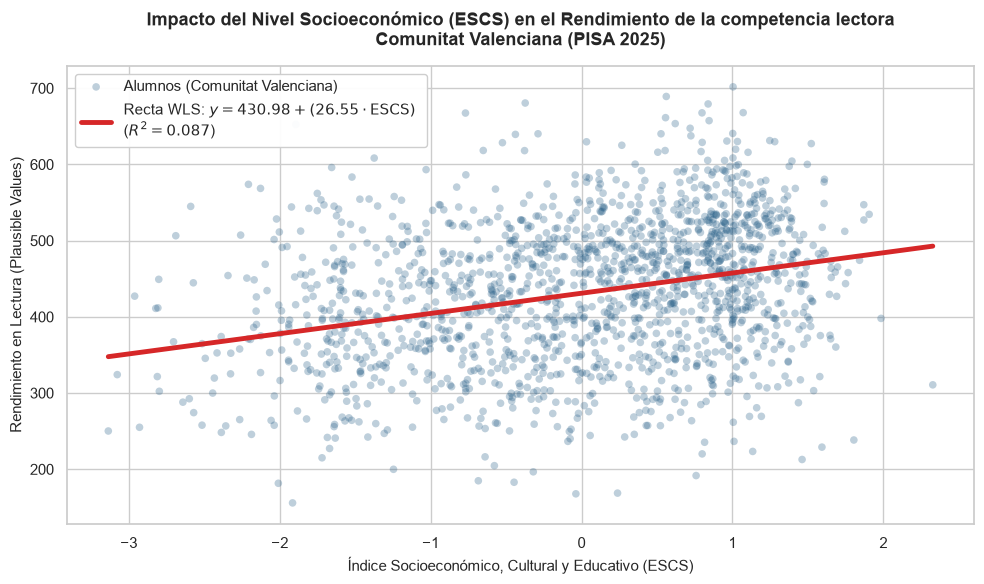

In [5]:
# 4. REPRESENTACIÓN GRÁFICA DE LOS RESULTADOS
# Activa el estilo visual estético de Seaborn (le da un fondo limpio con cuadrícula gris)
sns.set_theme(style="whitegrid")
# Crea una ventana o "lienzo" en blanco para dibujar el gráfico con un tamaño de 10x6 pulgadas
plt.figure(figsize=(10, 6))
# Dibujar la nube de puntos de los alumnos (usando PV1READ como base visual), 
# alpha=Controla la opacidad de los puntos en una escala de 0.0 (completamente invisible) a 1.0 (completamente sólido), 
# s=Define el tamaño de cada uno de los circulitos que representan a los estudiantes, 
plt.scatter(
    df_estudio1_limpio['ESCS'], 
    df_estudio1_limpio['PV1READ'], 
    alpha=0.3, 
    color="#2A6189", 
    edgecolors='none', 
    s=30,
    label='Alumnos (Comunitat Valenciana)'
)

# Generamos los valores (100 equidist) para pintar la recta final basada en nuestra var indep ESCS y los promedios obtenidos de PVREAD con la recta final
x_vals = np.linspace(df_estudio1_limpio['ESCS'].min(), df_estudio1_limpio['ESCS'].max(), 100)
y_vals = intercepto_final + pendiente_final * x_vals

# Trazar la línea de regresión ponderada oficial
plt.plot(
    x_vals, 
    y_vals, 
    color='#d62728', 
    linewidth=3.5, 
    # :.2f para redondear y mostrar un número con decimales de forma limpia
    label=f'Recta WLS: $y = {intercepto_final:.2f} + ({pendiente_final:.2f} \\cdot \\text{{ESCS}})$ \n($R^2 = {r2_final:.3f}$)'
)

# Personalizar el diseño del gráfico
plt.title('Impacto del Nivel Socioeconómico (ESCS) en el Rendimiento de la competencia lectora\nComunitat Valenciana (PISA 2025)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Índice Socioeconómico, Cultural y Educativo (ESCS)', fontsize=11)
plt.ylabel('Rendimiento en Lectura (Plausible Values)', fontsize=11)
# Muestra la leyenda flotante en la esquina superior izquierda del gráfico
plt.legend(frameon=True, facecolor='white', framealpha=0.95, loc='upper left', fontsize=11)
# Organiza los márgenes automáticamente para que las etiquetas de los ejes no se salgan del marco
plt.tight_layout()
plt.savefig("imgs/grafico_escs.png", dpi=200, bbox_inches="tight")

# Mostrar la visualización
plt.show()